## Вклад отдельного признака в прогноз цены дома

Гипотеза 1: добавление признака TotalBsmtSF помогает модели.

Гипотеза 2: Если два дома построены в одном году, сведения о реконструкции могут улучшить прогноз сверх признака Age

Все модели сравниваю на одних и тех же пяти фолдах, seed 42, метрика RMSE логарифмов

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

baseline = pd.read_csv('../outputs/baseline.csv', index_col='Id')
ablations = pd.read_csv('../outputs/ablations.csv', index_col='Id')
prices = pd.read_csv('../data/raw/train.csv', index_col='Id')['SalePrice']

In [2]:
pred = ablations.drop(columns='fold').assign(
    hw1_linear=baseline['log_area'],
    hw1_knn=baseline['knn_20'],
)
log_pred = np.log(pred)

log_price = np.log(prices.loc[pred.index])
scores = log_pred.sub(log_price, axis=0).pow(2).groupby(ablations['fold']).mean().pow(0.5)
summary = scores.T.assign(mean=scores.mean(), std=scores.std())
summary.sort_values(by='mean').round(4).style.background_gradient(cmap='Reds')

fold,1,2,3,4,5,mean,std
linear_no_LotFrontage,0.141700,0.152200,0.188500,0.144800,0.147800,0.155000,0.019100
linear_no_GarageArea,0.142800,0.152700,0.191200,0.146600,0.147700,0.156200,0.019900
linear,0.142100,0.152300,0.194900,0.145900,0.147700,0.156600,0.021700
linear_no_GarageCars,0.141200,0.151900,0.196000,0.145400,0.148800,0.156700,0.022300
linear_no_TotalBsmtSF,0.148600,0.154900,0.180900,0.149900,0.152900,0.157400,0.013400
linear_no_KitchenQual,0.145300,0.149500,0.194800,0.148600,0.149600,0.157600,0.020900
linear_no_RemodelYears,0.142500,0.155500,0.197900,0.149100,0.148100,0.158600,0.022400
hw1_linear,0.148900,0.158100,0.184300,0.152500,0.153200,0.159400,0.014300
linear_no_Age,0.144500,0.158300,0.195200,0.151200,0.152100,0.160300,0.020100
linear_no_OverallQual,0.149300,0.158700,0.208100,0.151700,0.153000,0.164200,0.024800


Наилучшие результаты показывают линейная модель без LotFrontage, GarageArea и обычная (в том числе с TotalBsmtSF). std по фолдам у линейных моделей выше. 

linear


,mean_rmse_increase,folds_worse_without_feature
LogArea,0.02423,5
Neighborhood,0.01161,5
OverallQual,0.00761,5
Age,0.00370,5
RemodelYears,0.00206,5
KitchenQual,0.00102,3
TotalBsmtSF,0.00089,4
GarageCars,0.00011,2
GarageArea,-0.00034,4
LotFrontage,-0.00154,1


knn_k=20


,mean_rmse_increase,folds_worse_without_feature
LogArea,0.03366,5
TotalBsmtSF,0.01235,5
OverallQual,0.01123,5
Age,0.00576,4
RemodelYears,0.00079,4
Neighborhood,0.00077,3


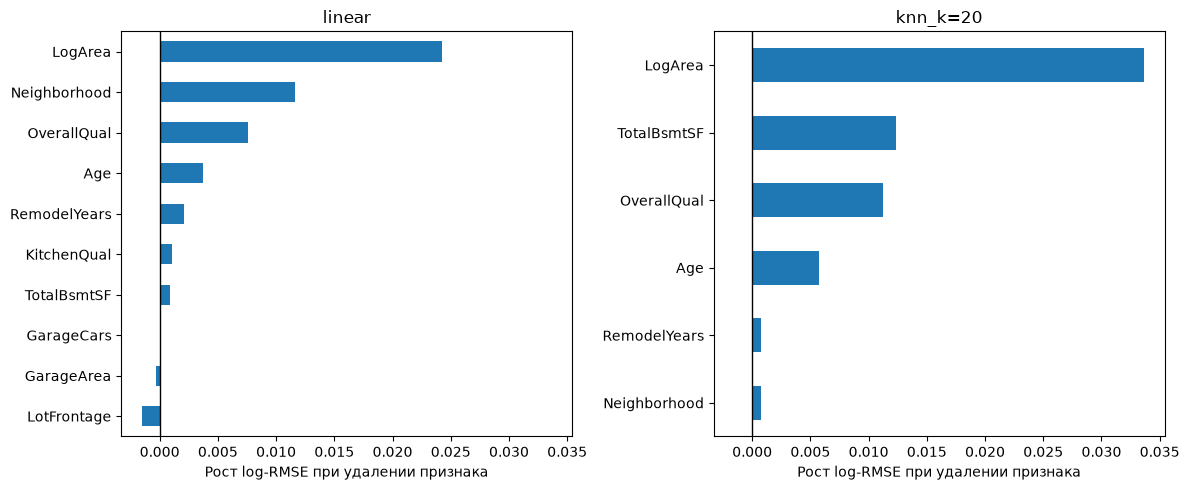

In [3]:
# тут я использовал ИИ, потому что у меня лапки и не получалось написать то, что хотел
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

for ax, model, prefix, suffix in [
    (axes[0], 'linear', 'linear_no_', ''),
    (axes[1], 'knn_k=20', 'knn_no_', '_k=20'),
]:
    cols = [c for c in scores if c.startswith(prefix) and c.endswith(suffix)]
    delta = scores[cols].sub(scores[model], axis=0)
    delta.columns = delta.columns.str.removeprefix(prefix).str.removesuffix(suffix)

    importance = pd.DataFrame({
        'mean_rmse_increase': delta.mean(),
        'folds_worse_without_feature': delta.gt(0).sum(),
    }).sort_values('mean_rmse_increase')

    print(model)
    display(importance.iloc[::-1].round(5))
    importance['mean_rmse_increase'].plot.barh(ax=ax, title=model)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_xlabel('Рост log-RMSE при удалении признака')

plt.tight_layout()
plt.show()

## Выводы

Добавление площади подвала и времени до реконструкции log RMSE линейной модели снизился с 0.1594 (дз 1) до 0.1566 (linear). Реконструкция помогла на всех пяти фолдах (среднее улучшение 0.00206). Площадь подвала помогла на четырёх фолдах из пяти (улучшение 0.00089). Лучший параметр, без которого качество хуже - LogArea (неудивительно, ср. улучшение 0.02423)

Для KNN при фиксированном k=20 площадь подвала оказалась второй по важности: её удаление увеличило ошибку и ухудшило результат на каждом фолде (на 0.01235). Самой важной величиной опять же была (LogArea). Это наводит на мысль задать бОльшие веса для LogArea, TotalBsmtSF и меньшие для Neighborhood. Лучший KNN среди проверенных значений k получился при k=10 (0.1683).

Самый низкий результат во всей таблице дала линейная модель без LotFrontage (0.1550).